  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 36.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 48.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 27.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 33.4 MB/s  0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4118 sha256=e791d1e6e748ca13426cdbee22f6b6c201c9334eb653ff367b6627106a50203e
  Stored in directory: /root/.cache/pip/wheels/7e/16/46/9477f188924292d3bf1fb8fb42844201591abfc19b7ba6d868
Successfully built autograd-gamma
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [ISLP]
            Murder  Assault  UrbanPop  Rape
rownames                                   
Alabama       13.2      236        58  21.2
Alaska        10.0      263        48  44.5
Arizona        8.1  

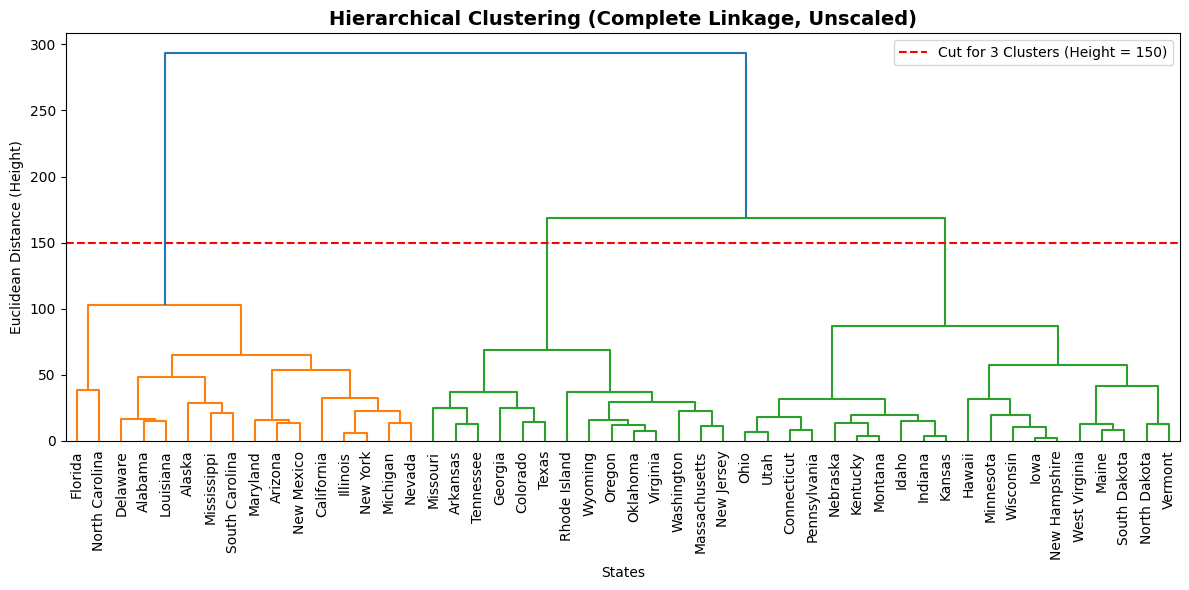

--- (b) Unscaled Clusters (3 Clusters) ---
Cluster 1 (16 states): Alabama, Alaska, Arizona, California, Delaware, Florida, Illinois, Louisiana, Maryland, Michigan, Mississippi, Nevada, New Mexico, New York, North Carolina, South Carolina

Cluster 2 (14 states): Arkansas, Colorado, Georgia, Massachusetts, Missouri, New Jersey, Oklahoma, Oregon, Rhode Island, Tennessee, Texas, Virginia, Washington, Wyoming

Cluster 3 (20 states): Connecticut, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Minnesota, Montana, Nebraska, New Hampshire, North Dakota, Ohio, Pennsylvania, South Dakota, Utah, Vermont, West Virginia, Wisconsin



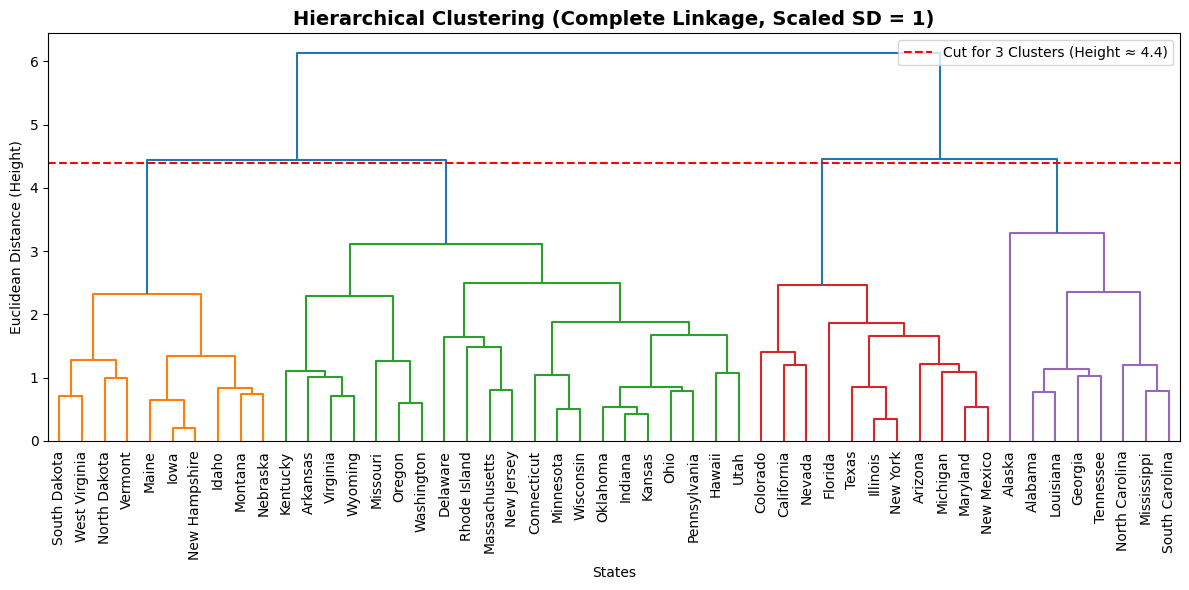

--- (c) Scaled Clusters (3 Clusters) ---
Cluster 1 (8 states): Alabama, Alaska, Georgia, Louisiana, Mississippi, North Carolina, South Carolina, Tennessee

Cluster 2 (11 states): Arizona, California, Colorado, Florida, Illinois, Maryland, Michigan, Nevada, New Mexico, New York, Texas

Cluster 3 (31 states): Arkansas, Connecticut, Delaware, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Massachusetts, Minnesota, Missouri, Montana, Nebraska, New Hampshire, New Jersey, North Dakota, Ohio, Oklahoma, Oregon, Pennsylvania, Rhode Island, South Dakota, Utah, Vermont, Virginia, Washington, West Virginia, Wisconsin, Wyoming

--- Cross-Tabulation: Unscaled vs. Scaled Clusters ---
Cluster_Scaled    1  2   3
Cluster_Unscaled          
1                 6  9   1
2                 2  2  10
3                 0  0  20


In [ ]:
!pip install ISLP

import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree

# Load the USArrests dataset from R datasets via statsmodels (standard ISLP method)
USArrests = sm.datasets.get_rdataset("USArrests").data
states = USArrests.index

# Show the first 5 lines
print(USArrests.head())

# ==============================================================================
# (a) Hierarchical clustering with complete linkage and Euclidean distance (Unscaled)
# ==============================================================================
hc_complete = linkage(USArrests, method='complete', metric='euclidean')

plt.figure(figsize=(12, 6))
dendrogram(
    hc_complete,
    labels=states,
    leaf_rotation=90,
    leaf_font_size=10
)
plt.title('Hierarchical Clustering (Complete Linkage, Unscaled)', fontsize=14, fontweight='bold')
plt.xlabel('States')
plt.ylabel('Euclidean Distance (Height)')
plt.axhline(y=150, color='red', linestyle='--', label='Cut for 3 Clusters (Height = 150)')
plt.legend()
plt.tight_layout()
plt.show()

# ==============================================================================
# (b) Cut the unscaled dendrogram to obtain 3 distinct clusters
# ==============================================================================
clusters_unscaled = cut_tree(hc_complete, n_clusters=3).flatten()

unscaled_results = pd.DataFrame({
    'State': states,
    'Cluster_Unscaled': clusters_unscaled + 1
})

print("--- (b) Unscaled Clusters (3 Clusters) ---")
for c in range(1, 4):
    state_list = unscaled_results[unscaled_results['Cluster_Unscaled'] == c]['State'].tolist()
    print(f"Cluster {c} ({len(state_list)} states): {', '.join(state_list)}\n")

# ==============================================================================
# (c) Hierarchical clustering after scaling variables to standard deviation 1
# ==============================================================================
scaler = StandardScaler()
USArrests_scaled = scaler.fit_transform(USArrests)

hc_complete_scaled = linkage(USArrests_scaled, method='complete', metric='euclidean')

plt.figure(figsize=(12, 6))
dendrogram(
    hc_complete_scaled,
    labels=states,
    leaf_rotation=90,
    leaf_font_size=10
)
plt.title('Hierarchical Clustering (Complete Linkage, Scaled SD = 1)', fontsize=14, fontweight='bold')
plt.xlabel('States')
plt.ylabel('Euclidean Distance (Height)')
plt.axhline(y=4.4, color='red', linestyle='--', label='Cut for 3 Clusters (Height ≈ 4.4)')
plt.legend()
plt.tight_layout()
plt.show()

# Print the 3 clusters after scaling to compare directly with part (b)
clusters_scaled = cut_tree(hc_complete_scaled, n_clusters=3).flatten()
scaled_results = pd.DataFrame({
    'State': states,
    'Cluster_Scaled': clusters_scaled + 1
})

print("--- (c) Scaled Clusters (3 Clusters) ---")
for c in range(1, 4):
    state_list = scaled_results[scaled_results['Cluster_Scaled'] == c]['State'].tolist()
    print(f"Cluster {c} ({len(state_list)} states): {', '.join(state_list)}\n")

# Compare cluster sizes side-by-side
comparison = pd.crosstab(
    unscaled_results['Cluster_Unscaled'],
    scaled_results['Cluster_Scaled']
)
print("--- Cross-Tabulation: Unscaled vs. Scaled Clusters ---")
print(comparison)
